# 03 — Visualising the graph
Lecture 1, ~19-24% (search: "nicely visualize these expressions"). Phase 1, item 3 in [PLAN](../knowledge/PLAN.md). Previous: [02-value-object](../knowledge/notes/02-value-object.md).

**Where this fits.** Item 2 gave every `Value` a receipt. Printing it works for 3 nodes and stops working for 30. Today you draw it. Item 4 fills in a slope on every box of this same picture, by hand, starting from the end.

**Done when** `draw_dot(L)` shows `a`, `b`, `c`, `e`, `d`, `f`, `L` with the right numbers, and you can point at the picture and say which way data flows and which way slopes will flow.

Pure Python. `graphviz` is only used for drawing.

## 0. Check the drawing tool
The pip `graphviz` package only calls a separate program named `dot`. If this prints `None`, run `! sudo apt install -y graphviz` in Claude Code, then restart the kernel. Sections 1-2 work without it.

In [7]:
import shutil

print(shutil.which("dot"))  # a path means you can draw

/usr/bin/dot


## 1. Your Value, plus a label
Copy your `Value` class from notebook 02 into the cell below. Then add one field: `label`, an empty string by default, so you can pass a name like `Value(2.0, label='a')`.

Question: should `__add__` and `__mul__` give their result a label? Who knows the name `e` at that moment?

In [8]:
class Value:
    def __init__(self, data, label=""):
        self.data = data
        # this field will be used to track the previous Value in the computational graph
        self._prev = ()
        # this field will be used to track the operation that produced this Value
        self._op = ""
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # create a new Value object to represent the result of the addition
        out = Value(self.data + other.data, label=f"({self.label}+{other.label})")
        # set the _prev field to track the previous Values in the computational graph
        out._prev = (self, other)
        # set the _op field to indicate that this Value was produced by addition
        out._op = "+"
        return out

    def __mul__(self, other):
        # create a new Value object to represent the result of the multiplication
        out = Value(self.data * other.data, label=f"({self.label}*{other.label})")
        # set the _prev field to track the previous Values in the computational graph
        out._prev = (self, other)
        # set the _op field to indicate that this Value was produced by multiplication
        out._op = "*"
        return out

## 2. One layer deeper
Build this, giving every value its label. For `e` and `d`, set `.label` after the operation creates them.

```
a = 2.0    b = -3.0    c = 10.0    f = -2.0
e = a * b
d = e + c
L = d * f
```

**Predict `L.data` before you run it.** Then check it with your `traverse_graph` from notebook 02.

In [9]:
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
f = Value(-2.0, label="f")

e = a * b  # Value(data=-6.0, label="(a*b)")
d = e + c  # Value(data=4.0, label="((a*b)+c)")
L = d * f  # Value(data=-8.0, label="(((a*b)+c)*f)")


def traverse_graph(value):
    print(value._op)
    for node in value._prev:
        print(node, node.label)
        traverse_graph(node)


traverse_graph(L)

*
Value(data=4.0) ((a*b)+c)
+
Value(data=-6.0) (a*b)
*
Value(data=2.0) a

Value(data=-3.0) b

Value(data=10.0) c

Value(data=-2.0) f



## 3. The drawing helper (scaffolding)
Run this cell, don't study it. Two things worth knowing:
- `trace` is your `traverse_graph`, except it collects nodes into a set and doesn't print them.
- The small `+` / `*` circles are **not** `Value`s. The drawing adds them so you can see which op made which box. Only the boxes are real `Value`s.

In [10]:
# SCAFFOLDING (written by Claude): draws the receipt. You don't need to type this.
# Adapted from Karpathy's draw_dot in lectures/micrograd/micrograd_lecture_first_half_roughly.ipynb
from graphviz import Digraph


def trace(root):
    # walk _prev from the root (same idea as your traverse_graph), collect every node and edge once
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})  # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        label = getattr(n, "label", "")  # works before you've added .label
        text = f"{{ {label} | data {n.data:.4f} }}"
        if hasattr(n, "grad"):  # shows up once you add .grad in item 4
            text = f"{{ {label} | data {n.data:.4f} | grad {n.grad:.4f} }}"
        dot.node(name=uid, label=text, shape="record")  # a box per Value
        if n._op:
            dot.node(
                name=uid + n._op, label=n._op
            )  # a small op node (not a real Value)
            dot.edge(uid + n._op, uid)
    for child, parent in edges:
        dot.edge(str(id(child)), str(id(parent)) + parent._op)
    return dot

## 4. Draw it
Call `draw_dot(L)`. Check it against section 2: every box, every op, every arrow. Read it left to right: that's the forward pass.

Question: item 4 starts at `L` and works out "how much does L care about this box?" for each box. Which box do you fill in first, and which last?

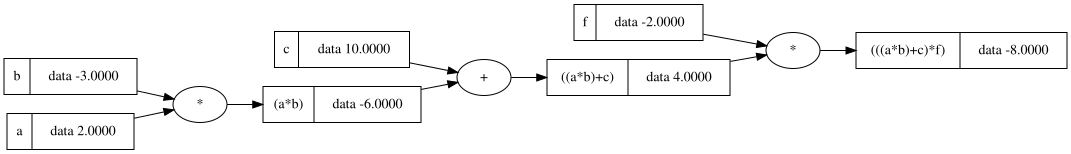

In [ ]:
# a = 2.0, b = -3.0, c = 10.0, f = -2.0
# e = a * b = -6.0
# d = e + c = 4.0
# L = d * f = -8.0

draw_dot(L)

# L's label: (((a*b)+c)*f)
#
# Which box do you fill in first, and which last?
# First: L, the loss. Last: a and b, the leaves furthest from L.
# Slopes start at L and move right to left, from each box to the boxes that made it (parent to child).
#
# What goes in L's box? If I nudge L by 0.001, L moves by exactly 0.001.
# Slope = 0.001 / 0.001 = 1. So L's box gets 1.
#
# Can you work out e's slope before you know d's? Why or why not?
# (Reasoning corrected by Claude at your request. Your version said c's slope = 1.)
#
# No. e only reaches L through d, so e's effect on L depends on d's.
# Fill the boxes in right to left, one at a time. You can't skip a box.
#
# L = d * f     L's slope = 1
#   d's slope = f.data * L's slope = -2 * 1 = -2
#   f's slope = d.data * L's slope =  4 * 1 =  4
#   For *, each side's slope uses the OTHER side's data, not its .grad.
#   (You wrote: "set one's .grad to other's .grad times L's slope".)
#
# d = e + c     + passes d's slope through unchanged
#   c's slope = 1 * d's slope = -2
#   e's slope = 1 * d's slope = -2
#   (You wrote: "c's slope will be just one". The 1 is how much d moves when c moves.
#    It isn't how much L moves. L moves 1 * d's slope = -2.)
#
# Check: c = 10.001 -> d = 4.001 -> L = 4.001 * -2 = -8.002
#   L moved -0.002 for a +0.001 push, so c's slope is -2. Skipping d drops the "* f".
#
# e = a * b     a's and b's slopes come next. That's item 4.
#
# Why can't e see d? Which way does _prev point?
# _prev points back, to the inputs. When e was created, it only knew a and b.
# Nothing points forward: e has no idea it will be used in d = e + c, or anywhere else.

## 5. Break it
Predict each one, then run it.

1. `draw_dot(e)`. Which boxes disappear? Why can't the drawing see them from `e`?
2. `g = a * a`, then `draw_dot(g)`. Your `_prev` holds `a` twice. How many arrows go from `a` into the `*`? (Look at what `trace` stores edges in.)
3. `h = a * b + a`, then `draw_dot(h)`. How many boxes are labelled `a`? How many arrows leave it? Is this a tree like an AST, or something else?
4. Change `a.data = 100.0`, then `draw_dot(L)` again. Which numbers in the picture change? Does that match what you found in notebook 02, section 6, Q4?

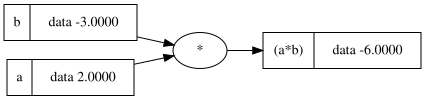

In [12]:
# Break 1. Prediction: only a and b, with * between them. c, f, d and L disappear.
# OPEN: why can't the drawing see them from e? Which way does _prev point?
draw_dot(e)

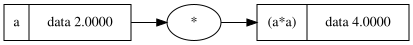

In [ ]:
# Break 2. Prediction: two a boxes.
# Saw: ONE a box, one (a*a) box. Two arrows in total: a -> *, and * -> (a*a).
# Why one arrow out of a: _prev is (a, a), so trace adds the edge (a, g) twice.
# A set keeps only one copy, so the second arrow disappears.
# The picture hides that a was used twice. Remember this for item 6.
g = a * a
draw_dot(g)

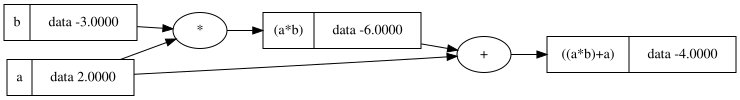

In [14]:
# Break 3. Prediction: one box labelled a, with two arrows leaving it (one into *, one into +).
# Tree or not? Not a tree. In a tree every node has exactly one parent.
# Here a feeds two ops, so it has two parents. It's a graph: arrows only go one way, and there are no loops.
# (Corrected by Claude: your answer cited g = a * a, but that's break 2, and its picture has one arrow, not two.)
h = a * b + a
draw_dot(h)

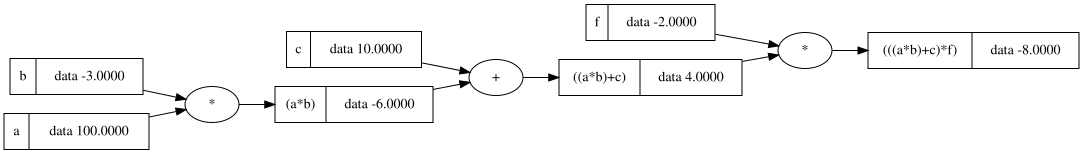

In [15]:
# Break 4. Prediction: L stays -8. The math ran once, when each Value was created.
# Only a's box changes, to 100. To get a new L, build the expression again (a new forward pass).
# Run this one last: it changes a for every cell you run after it.
a.data = 100.0
draw_dot(L)

## Review (Claude, 2026-11-24, round 5): pick up here
At your request, Claude wrote out the corrected reasoning in cell 10 (the slopes of `L`, `d`, `f`, `c`, `e`) and the break 2 answer. Your original mistakes are quoted there. This was the last-resort step: the answer was given, not worked out.

**Left:** explain item 3 back in your own words. Then item 4: `a`'s and `b`'s slopes, using the rule in cell 10.

## Notes / findings
Your own words: what do the boxes, the op circles and the arrows each represent? Which direction will slopes travel through this picture, and why that direction?

Each box is a `Value`, showing its `label` and its `data`. Each op circle is the operation that made the box to its right out of the boxes feeding into it. The circle isn't a `Value`; the drawing adds it. An arrow means data flowing: from a box into an op that uses it, and from an op to the box it produced. Data flows left to right. Slopes travel right to left: they start at `L` and pass from each box back to the boxes that made it (parent to child), until every box has one.